In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5


In [2]:
# ============================================================================
# CELL 1: Installation et imports (INDÉPENDANT)
# ============================================================================

!pip install joblib seaborn scikit-learn -q

import os
import warnings
import logging
import glob
import gc
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

os.environ['HDF5_PLUGIN_PATH'] = '/tmp/hdf5_plugins'
os.makedirs('/tmp/hdf5_plugins', exist_ok=True)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['CUDA_DEVICE_ORDER'] = 'PCI_BUS_ID'

warnings.filterwarnings('ignore')
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from scipy.signal import find_peaks

print('='*60)
print('DISHWASHER NILM - Version améliorée (50 epochs)')
print('='*60)
print(f'TensorFlow: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')

E0000 00:00:1777123927.600304      22 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777123927.771352      22 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777123928.806631      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777123928.806679      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777123928.806682      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777123928.806684      22 computation_placer.cc:177] computation placer already registered. Please check linka

DISHWASHER NILM - Version améliorée (50 epochs)
TensorFlow: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
# ============================================================================
# CELL 2: Configuration DISHWASHER (INDÉPENDANT)
# ============================================================================

class Config:
    """Configuration spécifique pour le DISHWASHER"""
    
    # Paramètres du modèle
    WINDOW_SIZE = 599          # 599 points = 59.9 minutes
    BATCH_SIZE = 256
    EPOCHS = 5               # 50 epochs
    LR = 1e-3
    VAL_SPLIT = 0.15
    SEED = 42
    FREQ = '6s'
    
    # Limites mémoire
    MAX_TRAIN_SAMPLES = 500_000
    MAX_TEST_SAMPLES = 100_000
    
    H5_PATH = None
    
    # PARAMÈTRES DISHWASHER
    DISHWASHER = {
        'name': 'Dishwasher',
        'meter': 1,
        'threshold': 10,
        'max_power': 3230,
        'mean_on': 700,
        'std_on': 1000,
        'color': '#4ECDC4',
        'window_minutes': 90
    }
    
    # Configuration des maisons
    UKDALE_HOUSES = {
        'house_1': {
            'name': 'UKDALE-1',
            'house_id': 1,
            'train': ('2013-04-01', '2014-03-31'),
            'test': ('2014-04-01', '2014-05-01'),
        },
        'house_2': {
            'name': 'UKDALE-2',
            'house_id': 2,
            'test': ('2013-07-28', '2013-08-11'),
        },
        'house_5': {
            'name': 'UKDALE-5',
            'house_id': 5,
            'test': ('2014-06-20', '2014-06-30'),
        }
    }
    
    @classmethod
    def get_meter(cls):
        return f"meter{cls.DISHWASHER['meter']}"
    
    @classmethod
    def get_threshold(cls):
        return cls.DISHWASHER['threshold']
    
    @classmethod
    def get_window_minutes(cls):
        return cls.DISHWASHER['window_minutes']


# Trouver le fichier H5
h5_files = glob.glob('/kaggle/input/**/*.h5', recursive=True)
if h5_files:
    Config.H5_PATH = h5_files[0]
    print(f"✅ Fichier trouvé: {Config.H5_PATH}")
else:
    print("❌ Aucun fichier .h5 trouvé!")

tf.random.set_seed(Config.SEED)
np.random.seed(Config.SEED)

print("="*60)
print("CONFIGURATION DISHWASHER")
print("="*60)
print(f"Appareil: {Config.DISHWASHER['name']}")
print(f"Compteur: meter{Config.DISHWASHER['meter']}")
print(f"Seuil ON/OFF: {Config.DISHWASHER['threshold']} W")
print(f"Window size: {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")
print(f"Batch size: {Config.BATCH_SIZE}")
print(f"Epochs: {Config.EPOCHS}")

✅ Fichier trouvé: /kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5
CONFIGURATION DISHWASHER
Appareil: Dishwasher
Compteur: meter1
Seuil ON/OFF: 10 W
Window size: 599 pts = 60 min
Batch size: 256
Epochs: 5


In [4]:
# ============================================================================
# CELL 3: Chargeur de données UK-DALE (INDÉPENDANT)
# ============================================================================

class UKDALEDataLoader:
    """Chargeur de données UK-DALE spécialisé DISHWASHER"""
    
    def __init__(self, h5_path):
        self.h5_path = h5_path
        self._cache = {}
    
    def read_meter(self, building, meter, max_points=None):
        cache_key = f"b{building}_{meter}"
        if cache_key in self._cache:
            return self._cache[cache_key]
        
        try:
            key = f'building{building}/elec/{meter}'
            s = pd.read_hdf(self.h5_path, key=key)
            if isinstance(s, pd.DataFrame):
                s = s.iloc[:, 0]
            s = s.astype(np.float32)
            s = s[~s.index.duplicated(keep='first')]
            s = s.sort_index()
            if max_points and len(s) > max_points:
                s = s.iloc[:max_points]
            self._cache[cache_key] = s
            return s
        except Exception:
            return None
    
    def _to_tz_aware(self, date_str, tz='Europe/London'):
        if date_str is None:
            return None
        dt = pd.Timestamp(date_str)
        if dt.tz is None:
            dt = dt.tz_localize(tz)
        return dt
    
    def load_house_data(self, house_key, mode='train', max_samples=None):
        if house_key not in Config.UKDALE_HOUSES:
            raise ValueError(f"Maison {house_key} non trouvée")
        
        house_config = Config.UKDALE_HOUSES[house_key]
        house_id = house_config['house_id']
        
        if mode == 'train':
            if 'train' not in house_config:
                return None
            start_date = self._to_tz_aware(house_config['train'][0])
            end_date = self._to_tz_aware(house_config['train'][1])
        else:
            if 'test' not in house_config:
                return None
            start_date = self._to_tz_aware(house_config['test'][0])
            end_date = self._to_tz_aware(house_config['test'][1])
        
        print(f"\n{'='*50}")
        print(f"{mode.upper()}: {house_config['name']}")
        print(f"Période: {start_date.date()} → {end_date.date()}")
        print(f"{'='*50}")
        
        dw_meter = Config.get_meter()
        all_meters = {}
        monitored_meters = []
        
        # Dishwasher
        s = self.read_meter(house_id, dw_meter)
        if s is not None and len(s) > 0:
            all_meters[dw_meter] = s
            monitored_meters.append(dw_meter)
            print(f"✅ {dw_meter}: {len(s):,} points")
        else:
            print(f"❌ {dw_meter} non trouvé!")
            return None
        
        # Autres compteurs pour la somme
        for i in range(1, 20):
            meter = f"meter{i}"
            if meter != dw_meter and meter not in all_meters:
                s = self.read_meter(house_id, meter)
                if s is not None and len(s) > 0:
                    all_meters[meter] = s
                    monitored_meters.append(meter)
        
        print(f"✅ {len(all_meters)} compteurs chargés")
        
        # Grille temporelle
        start_dates = [s.index.min() for s in all_meters.values()]
        end_dates = [s.index.max() for s in all_meters.values()]
        common_start = max(start_dates)
        common_end = min(end_dates)
        
        grid_start = max(common_start, start_date)
        grid_end = min(common_end, end_date)
        grid = pd.date_range(grid_start, grid_end, freq=Config.FREQ, tz='Europe/London')
        
        print(f"Grille: {len(grid):,} points")
        
        # DataFrame
        df_dict = {}
        for meter, series in all_meters.items():
            df_dict[meter] = series.reindex(grid, method='nearest', tolerance=Config.FREQ).fillna(0)
        
        df = pd.DataFrame(df_dict)
        
        if max_samples and len(df) > max_samples:
            df = df.iloc[:max_samples]
        
        # Statistiques dishwasher
        dw_power = df[dw_meter].values
        threshold = Config.get_threshold()
        
        print(f"\n📊 DISHWASHER ({dw_meter}) - {mode}:")
        print(f"   Max: {dw_power.max():.0f} W")
        print(f"   Moy: {dw_power.mean():.1f} W")
        print(f"   ON (> {threshold}W): {(dw_power > threshold).mean()*100:.2f}%")
        
        return {
            'name': house_config['name'],
            'house_id': house_id,
            'house_key': house_key,
            'df': df,
            'dw_meter': dw_meter,
            'monitored_meters': monitored_meters,
        }
    
    def clear_cache(self):
        self._cache.clear()
        gc.collect()


if Config.H5_PATH and os.path.exists(Config.H5_PATH):
    loader = UKDALEDataLoader(Config.H5_PATH)
    print("✅ Chargeur UK-DALE initialisé")
else:
    loader = None

✅ Chargeur UK-DALE initialisé


In [5]:
# ============================================================================
# CELL 4: Chargement des données (INDÉPENDANT)
# ============================================================================

print("\n" + "="*60)
print("CHARGEMENT DES DONNÉES DISHWASHER")
print("="*60)

if loader is None:
    print("❌ Chargeur non disponible")
    DATA_TRAIN = None
    DATA_TEST = None
else:
    print("\n📚 Données d'entraînement (house_1):")
    DATA_TRAIN = loader.load_house_data('house_1', mode='train', max_samples=Config.MAX_TRAIN_SAMPLES)
    
    print("\n🔬 Données de test (house_2):")
    DATA_TEST = loader.load_house_data('house_2', mode='test', max_samples=Config.MAX_TEST_SAMPLES)
    
    if DATA_TRAIN and DATA_TEST:
        print(f"\n✅ Données prêtes:")
        print(f"   Train: {DATA_TRAIN['df'].shape}")
        print(f"   Test:  {DATA_TEST['df'].shape}")

# Stocker les données pour les cellules suivantes
if DATA_TRAIN is not None:
    print("\n💾 Variables disponibles: DATA_TRAIN, DATA_TEST")


CHARGEMENT DES DONNÉES DISHWASHER

📚 Données d'entraînement (house_1):

TRAIN: UKDALE-1
Période: 2013-04-01 → 2014-03-31
✅ meter1: 21,837,636 points
✅ 19 compteurs chargés
Grille: 5,241,601 points

📊 DISHWASHER (meter1) - train:
   Max: 6484 W
   Moy: 382.0 W
   ON (> 10W): 99.28%

🔬 Données de test (house_2):

TEST: UKDALE-2
Période: 2013-07-28 → 2013-08-11
✅ meter1: 2,780,373 points
✅ 19 compteurs chargés
Grille: 201,601 points

📊 DISHWASHER (meter1) - test:
   Max: 5360 W
   Moy: 352.5 W
   ON (> 10W): 99.45%

✅ Données prêtes:
   Train: (500000, 19)
   Test:  (100000, 19)

💾 Variables disponibles: DATA_TRAIN, DATA_TEST


In [6]:
# ============================================================================
# CELL 5: Fonctions de fenêtrage et métriques NILM (INDÉPENDANT)
# ============================================================================

def create_windows(data, window_size=Config.WINDOW_SIZE, target_type='point'):
    """Crée des fenêtres glissantes"""
    values = data.values if isinstance(data, pd.Series) else np.array(data)
    values = values.astype(np.float32)
    
    pad = window_size // 2
    values_padded = np.pad(values, (pad, pad), 'constant', constant_values=0)
    
    X = np.array([
        values_padded[i:i + window_size]
        for i in range(len(values))
    ], dtype=np.float32)
    X = X[..., np.newaxis]
    
    if target_type == 'point':
        y = values
    else:
        y = np.array([
            values_padded[i:i + window_size]
            for i in range(len(values))
        ], dtype=np.float32)
    
    return X, y


class NILMMetrics:
    """Métriques NILM"""
    
    @staticmethod
    def estimation_accuracy(y_true, y_pred):
        numerator = np.sum(np.abs(y_true - y_pred))
        denominator = 2 * np.sum(y_true)
        if denominator == 0:
            return 1.0 if numerator == 0 else 0.0
        return float(np.clip(1 - numerator / denominator, 0, 1))
    
    @staticmethod
    def f_measure(y_true, y_pred, threshold):
        y_true_bin = (y_true > threshold).astype(int)
        y_pred_bin = (y_pred > threshold).astype(int)
        
        cm = confusion_matrix(y_true_bin, y_pred_bin, labels=[0, 1])
        if cm.shape != (2, 2):
            return 0.0
        
        tn, fp, fn, tp = cm.ravel()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        
        if precision + recall == 0:
            return 0.0
        return 2 * precision * recall / (precision + recall)
    
    @staticmethod
    def compute_all(y_true, y_pred, threshold):
        ea = NILMMetrics.estimation_accuracy(y_true, y_pred)
        fm = NILMMetrics.f_measure(y_true, y_pred, threshold)
        rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
        mae = np.mean(np.abs(y_true - y_pred))
        corr = np.corrcoef(y_true, y_pred)[0, 1] if y_true.std() > 0 else 0
        
        return {'ea': ea, 'fm': fm, 'rmse': rmse, 'mae': mae, 'corr': corr}


print(f"✅ create_windows() — window_size={Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")
print("✅ NILMMetrics défini")

✅ create_windows() — window_size=599 pts = 60 min
✅ NILMMetrics défini


In [7]:
# ============================================================================
# CELL 6: Architectures CNN (INDÉPENDANT)
# ============================================================================

def create_seq2point(window_size=Config.WINDOW_SIZE, l2_reg=1e-4):
    """Modèle Seq2Point CNN"""
    inputs = keras.Input(shape=(window_size, 1), name='mains_input')
    
    x = layers.Conv1D(30, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(30, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(40, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(1024, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='linear', name='power_output')(x)
    
    return keras.Model(inputs=inputs, outputs=outputs, name='seq2point')


def create_seq2seq(window_size=Config.WINDOW_SIZE, l2_reg=1e-4):
    """Modèle Seq2Seq CNN"""
    inputs = keras.Input(shape=(window_size, 1), name='mains_input')
    
    x = layers.Conv1D(30, 10, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(30, 8, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(40, 6, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Conv1D(50, 5, activation='relu', padding='same',
                      kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(1024, activation='relu',
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(window_size, activation='linear', name='seq_output')(x)
    
    return keras.Model(inputs=inputs, outputs=outputs, name='seq2seq')


s2p = create_seq2point()
s2s = create_seq2seq()

print(f"\n{'='*50}")
print("Architectures CNN - DISHWASHER")
print(f"{'='*50}")
print(f"Seq2Point: {s2p.count_params():,} paramètres")
print(f"Seq2Seq:   {s2s.count_params():,} paramètres")

I0000 00:00:1777124063.082624      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1777124063.088693      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Architectures CNN - DISHWASHER
Seq2Point: 30,709,049 paramètres
Seq2Seq:   31,321,999 paramètres


In [8]:
# ============================================================================
# CELL 7: Fonctions d'entraînement et prédiction (INDÉPENDANT)
# ============================================================================

def train_dishwasher(train_data, model_type='seq2point', epochs=Config.EPOCHS):
    """Entraîne le modèle dishwasher"""
    
    if train_data is None:
        print("❌ Données d'entraînement non disponibles")
        return None
    
    df = train_data['df']
    dw_meter = Config.get_meter()
    
    if dw_meter not in df.columns:
        print(f"❌ {dw_meter} non trouvé!")
        return None
    
    train_mains = df[train_data['monitored_meters']].sum(axis=1).values
    train_dw = df[dw_meter].values
    threshold = Config.get_threshold()
    
    print("\n" + "="*60)
    print(f"🚀 ENTRAÎNEMENT DISHWASHER - {model_type.upper()} ({epochs} epochs)")
    print("="*60)
    print(f"Compteur: {dw_meter}")
    print(f"Window: {Config.WINDOW_SIZE} pts ({Config.WINDOW_SIZE*6/60:.0f} min)")
    print(f"Epochs: {epochs}")
    print(f"\n📊 Statistiques entraînement:")
    print(f"   Mains - moy={train_mains.mean():.1f}W, max={train_mains.max():.0f}W")
    print(f"   Dishwasher - moy={train_dw.mean():.1f}W, max={train_dw.max():.0f}W")
    print(f"   ON (> {threshold}W): {(train_dw > threshold).mean()*100:.2f}%")
    
    # Normalisation
    mains_scaler = StandardScaler()
    dw_scaler = StandardScaler()
    
    mains_norm = mains_scaler.fit_transform(train_mains.reshape(-1, 1)).flatten()
    dw_norm = dw_scaler.fit_transform(train_dw.reshape(-1, 1)).flatten()
    
    # Fenêtres
    X, _ = create_windows(mains_norm, target_type='point')
    n = min(len(X), len(dw_norm))
    X = X[:n]
    
    if model_type == 'seq2point':
        y = dw_norm[:n]
    else:
        pad = Config.WINDOW_SIZE // 2
        padded = np.pad(dw_norm, (pad, pad), 'constant')
        y = np.array([padded[i:i + Config.WINDOW_SIZE] for i in range(n)], dtype=np.float32)
    
    # Split
    val_size = int(Config.VAL_SPLIT * n)
    X_train, X_val = X[:-val_size], X[-val_size:]
    y_train, y_val = y[:-val_size], y[-val_size:]
    
    print(f"\n  Train: {len(X_train):,} | Val: {len(X_val):,}")
    
    # Modèle
    model = create_seq2point() if model_type == 'seq2point' else create_seq2seq()
    model.compile(optimizer=keras.optimizers.Adam(Config.LR), loss='mse', metrics=['mae'])
    
    # Callbacks
    checkpoint_path = f'dishwasher_{model_type}.keras'
    callbacks_list = [
        callbacks.ModelCheckpoint(checkpoint_path, monitor='val_loss', save_best_only=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
        callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)
    ]
    
    # Entraînement
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=Config.BATCH_SIZE,
        callbacks=callbacks_list,
        verbose=1
    )
    
    # Charger le meilleur modèle
    if os.path.exists(checkpoint_path):
        model = keras.models.load_model(checkpoint_path)
        print(f"\n✅ Meilleur modèle chargé: {checkpoint_path}")
    
    return {
        'model': model,
        'mains_scaler': mains_scaler,
        'dw_scaler': dw_scaler,
        'history': history.history,
        'best_epoch': np.argmin(history.history['val_loss']) + 1
    }


def predict_dishwasher(mains_series, model_info, model_type='seq2point'):
    """Prédiction pour le dishwasher"""
    
    mains_norm = model_info['mains_scaler'].transform(mains_series.values.reshape(-1, 1)).flatten()
    X, _ = create_windows(mains_norm, target_type='point')
    
    predictions = []
    batch_size = 512
    
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size]
        pred = model_info['model'].predict(batch, verbose=0)
        
        if model_type == 'seq2point':
            predictions.append(pred.flatten())
        else:
            mid = Config.WINDOW_SIZE // 2
            predictions.append(pred[:, mid])
    
    pred_flat = np.concatenate(predictions)
    
    n = len(mains_series)
    if len(pred_flat) > n:
        pred_flat = pred_flat[:n]
    elif len(pred_flat) < n:
        pred_flat = np.pad(pred_flat, (0, n - len(pred_flat)), 'edge')
    
    return model_info['dw_scaler'].inverse_transform(pred_flat.reshape(-1, 1)).flatten()


print("✅ train_dishwasher() défini")
print("✅ predict_dishwasher() défini")

✅ train_dishwasher() défini
✅ predict_dishwasher() défini


In [9]:
# ============================================================================
# CELL 8: Entraînement Seq2Point et Seq2Seq (INDÉPENDANT)
# ============================================================================

print("\n" + "="*60)
print("ENTRAÎNEMENT DISHWASHER (50 EPOCHS)")
print("="*60)

if DATA_TRAIN is None:
    print("❌ Données d'entraînement non disponibles")
    dishwasher_models = None
else:
    dishwasher_models = {}
    
    # Entraînement Seq2Point
    print("\n" + "▶"*30)
    print("ENTRAÎNEMENT SEQ2POINT")
    print("▶"*30)
    dishwasher_models['seq2point'] = train_dishwasher(DATA_TRAIN, 'seq2point', epochs=Config.EPOCHS)
    
    # Entraînement Seq2Seq
    print("\n" + "▶"*30)
    print("ENTRAÎNEMENT SEQ2SEQ")
    print("▶"*30)
    dishwasher_models['seq2seq'] = train_dishwasher(DATA_TRAIN, 'seq2seq', epochs=Config.EPOCHS)
    
    print("\n" + "="*60)
    print("✅ ENTRAÎNEMENT TERMINÉ")
    print("="*60)
    if dishwasher_models['seq2point']:
        print(f"Seq2Point - Meilleure epoch: {dishwasher_models['seq2point']['best_epoch']}")
    if dishwasher_models['seq2seq']:
        print(f"Seq2Seq   - Meilleure epoch: {dishwasher_models['seq2seq']['best_epoch']}")


ENTRAÎNEMENT DISHWASHER (50 EPOCHS)

▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶
ENTRAÎNEMENT SEQ2POINT
▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶▶

🚀 ENTRAÎNEMENT DISHWASHER - SEQ2POINT (5 epochs)
Compteur: meter1
Window: 599 pts (60 min)
Epochs: 5

📊 Statistiques entraînement:
   Mains - moy=613.8W, max=12320W
   Dishwasher - moy=382.0W, max=6484W
   ON (> 10W): 99.28%

  Train: 425,000 | Val: 75,000
Epoch 1/5


I0000 00:00:1777124073.639048      75 service.cc:152] XLA service 0x7dd588003dc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777124073.639104      75 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1777124073.639111      75 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1777124074.667363      75 cuda_dnn.cc:529] Loaded cuDNN version 91002


   3/1661 ━━━━━━━━━━━━━━━━━━━━ 1:40 61ms/step - loss: 281.2492 - mae: 9.0800

I0000 00:00:1777124085.218520      75 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1661/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 16.6285 - mae: 1.2261
Epoch 1: val_loss improved from inf to 0.40828, saving model to dishwasher_seq2point.keras
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 104s 52ms/step - loss: 16.6205 - mae: 1.2256 - val_loss: 0.4083 - val_mae: 0.1302 - learning_rate: 0.0010
Epoch 2/5
1660/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.4340 - mae: 0.1654
Epoch 2: val_loss improved from 0.40828 to 0.34432, saving model to dishwasher_seq2point.keras
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 84s 51ms/step - loss: 0.4340 - mae: 0.1654 - val_loss: 0.3443 - val_mae: 0.1116 - learning_rate: 0.0010
Epoch 3/5
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.3888 - mae: 0.1563
Epoch 3: val_loss improved from 0.34432 to 0.30499, saving model to dishwasher_seq2point.keras
1661/1661 ━━━━━━━━━━━━━━━━━━━━ 84s 51ms/step - loss: 0.3888 - mae: 0.1563 - val_loss: 0.3050 - val_mae: 0.1528 - learning_rate: 0.0010
Epoch 4/5
1660/1661 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.3502 - m

In [10]:
# ============================================================================
# CELL 9: Évaluation sur house_2 (INDÉPENDANT)
# ============================================================================

def evaluate_dishwasher(test_data, model_info, model_type='seq2point'):
    """Évalue le modèle dishwasher sur les données de test"""
    
    if test_data is None:
        print("❌ Données de test non disponibles")
        return None
    
    df = test_data['df']
    dw_meter = Config.get_meter()
    threshold = Config.get_threshold()
    
    if dw_meter not in df.columns:
        print(f"❌ {dw_meter} non trouvé!")
        return None
    
    true_vals = df[dw_meter].values
    mains_vals = df[test_data['monitored_meters']].sum(axis=1).values
    
    n = min(len(true_vals), Config.MAX_TEST_SAMPLES)
    true_a = true_vals[:n]
    mains_s = pd.Series(mains_vals[:n])
    
    pred = predict_dishwasher(mains_s, model_info, model_type)
    pred = np.clip(pred, 0, None)
    
    min_len = min(len(true_a), len(pred))
    metrics = NILMMetrics.compute_all(true_a[:min_len], pred[:min_len], threshold)
    
    return metrics, pred[:min_len], true_a[:min_len]


if dishwasher_models and DATA_TEST:
    print("\n" + "="*60)
    print(f"ÉVALUATION DISHWASHER - {DATA_TEST['name']} (50 epochs)")
    print("="*60)
    
    for model_type, model_info in dishwasher_models.items():
        if model_info is None:
            continue
        metrics, pred, true_vals = evaluate_dishwasher(DATA_TEST, model_info, model_type)
        
        print(f"\n📊 {model_type.upper()} (50 epochs):")
        print(f"   EA = {metrics['ea']:.4f}")
        print(f"   FM = {metrics['fm']:.4f}")
        print(f"   RMSE = {metrics['rmse']:.1f} W")
        print(f"   MAE = {metrics['mae']:.1f} W")
        print(f"   Corr = {metrics['corr']:.4f}")
        
        # Sauvegarder
        dishwasher_models[model_type]['test_metrics'] = metrics
        dishwasher_models[model_type]['test_pred'] = pred
        dishwasher_models[model_type]['test_true'] = true_vals
else:
    print("❌ Modèles ou données de test non disponibles")


ÉVALUATION DISHWASHER - UKDALE-2 (50 epochs)

📊 SEQ2POINT (50 epochs):
   EA = 0.8927
   FM = 0.9972
   RMSE = 129.3 W
   MAE = 75.6 W
   Corr = 0.9790

📊 SEQ2SEQ (50 epochs):
   EA = 0.8884
   FM = 0.9972
   RMSE = 152.6 W
   MAE = 78.6 W
   Corr = 0.9575



VISUALISATIONS DISHWASHER (50 epochs)

📊 SEQ2POINT:


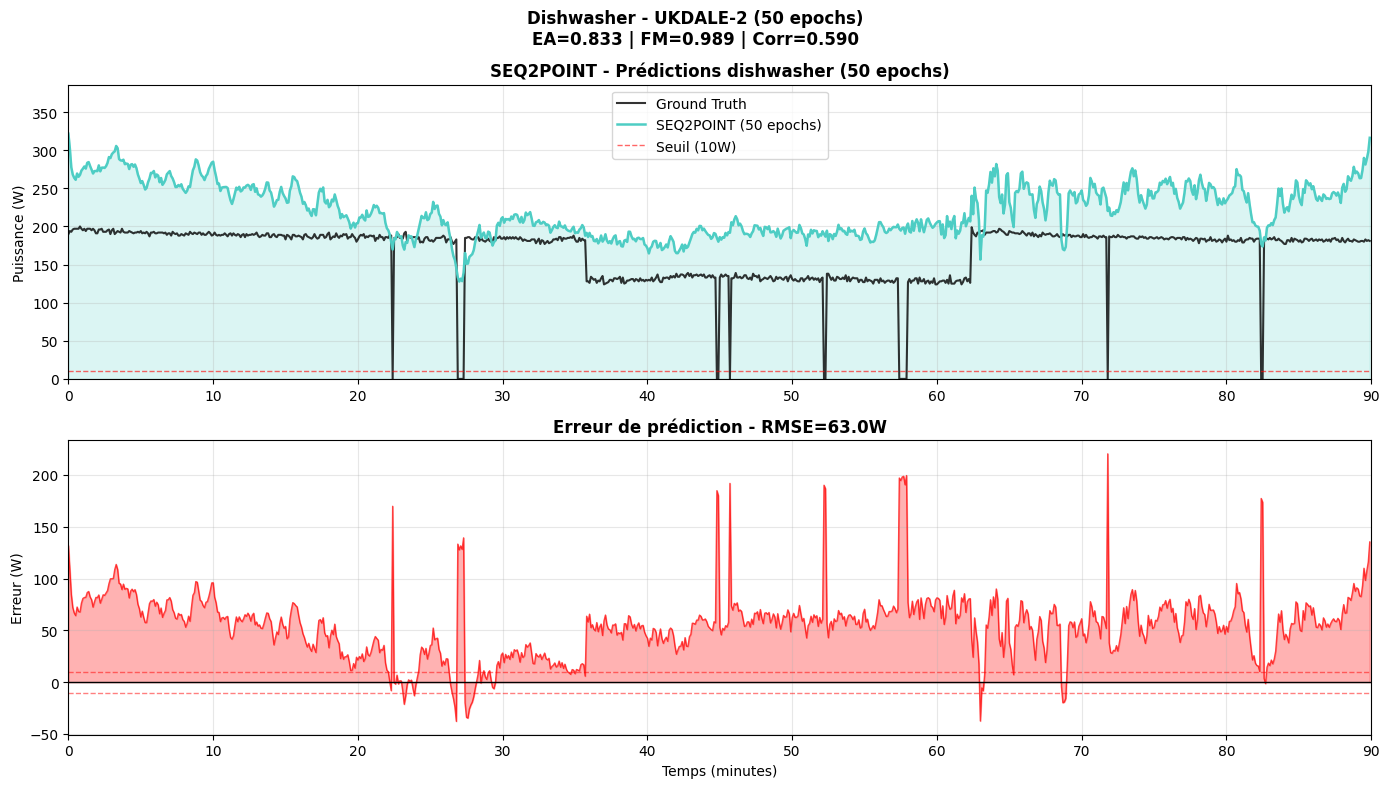

💾 dishwasher_seq2point_50epochs_ukdale-2.png

📊 SEQ2SEQ:


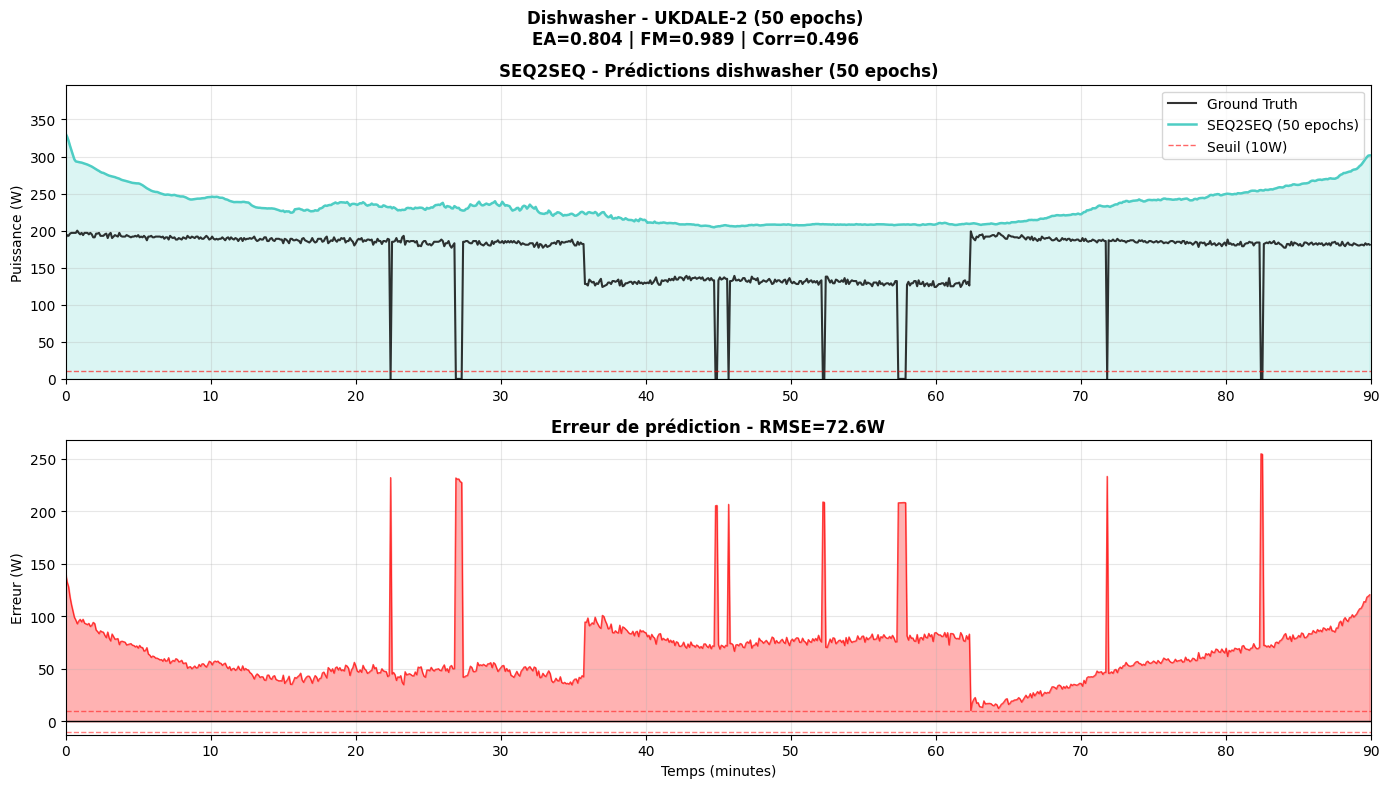

💾 dishwasher_seq2seq_50epochs_ukdale-2.png


In [11]:
# ============================================================================
# CELL 10: Visualisation des prédictions (INDÉPENDANT)
# ============================================================================

def plot_dishwasher_predictions(test_data, model_info, model_type='seq2point', window_minutes=90):
    """Visualise les prédictions du dishwasher"""
    
    df = test_data['df']
    dw_meter = Config.get_meter()
    threshold = Config.get_threshold()
    
    if dw_meter not in df.columns:
        print(f"❌ {dw_meter} non trouvé!")
        return
    
    power = df[dw_meter].values
    n_pts = window_minutes * 10
    
    # Trouver un cycle
    above = (power > threshold).astype(int)
    changes = np.diff(np.concatenate(([0], above, [0])))
    starts = np.where(changes == 1)[0]
    
    if len(starts) > 0:
        mid_idx = len(starts) // 2
        start_i = max(0, starts[mid_idx] - n_pts // 2)
    else:
        start_i = 0
    
    if start_i + n_pts > len(power):
        start_i = max(0, len(power) - n_pts)
    end_i = start_i + n_pts
    
    true_seg = power[start_i:end_i]
    time_min = np.arange(len(true_seg)) * 6 / 60
    
    mains_s = pd.Series(df[test_data['monitored_meters']].sum(axis=1).values[start_i:end_i])
    
    pred = predict_dishwasher(mains_s, model_info, model_type)
    pred = np.clip(pred, 0, None)
    
    min_len = min(len(true_seg), len(pred))
    true_seg = true_seg[:min_len]
    pred = pred[:min_len]
    
    metrics = NILMMetrics.compute_all(true_seg, pred, threshold)
    
    y_max = max(true_seg.max(), pred.max()) * 1.2
    if y_max < 100:
        y_max = threshold * 2
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    
    ax1 = axes[0]
    ax1.plot(time_min[:min_len], true_seg, color='black', lw=1.5, alpha=0.8, label='Ground Truth')
    ax1.plot(time_min[:min_len], pred, color='#4ECDC4', lw=1.8, label=f'{model_type.upper()} (50 epochs)')
    ax1.fill_between(time_min[:min_len], 0, pred, alpha=0.2, color='#4ECDC4')
    ax1.axhline(threshold, color='red', ls='--', lw=1, alpha=0.6, label=f'Seuil ({threshold}W)')
    ax1.set_ylabel('Puissance (W)')
    ax1.set_title(f'{model_type.upper()} - Prédictions dishwasher (50 epochs)', fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim([0, window_minutes])
    ax1.set_ylim([0, y_max])
    
    ax2 = axes[1]
    error = pred - true_seg
    ax2.plot(time_min[:min_len], error, color='red', lw=1, alpha=0.7)
    ax2.fill_between(time_min[:min_len], 0, error, alpha=0.3, color='red')
    ax2.axhline(0, color='black', ls='-', lw=1)
    ax2.axhline(threshold, color='red', ls='--', lw=1, alpha=0.5)
    ax2.axhline(-threshold, color='red', ls='--', lw=1, alpha=0.5)
    ax2.set_xlabel('Temps (minutes)')
    ax2.set_ylabel('Erreur (W)')
    ax2.set_title(f'Erreur de prédiction - RMSE={metrics["rmse"]:.1f}W', fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.set_xlim([0, window_minutes])
    
    plt.suptitle(f'Dishwasher - {test_data["name"]} (50 epochs)\n'
                 f'EA={metrics["ea"]:.3f} | FM={metrics["fm"]:.3f} | Corr={metrics["corr"]:.3f}',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    
    fname = f'dishwasher_{model_type}_50epochs_{test_data["name"].lower()}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"💾 {fname}")
    
    return metrics


if dishwasher_models and DATA_TEST:
    print("\n" + "="*60)
    print("VISUALISATIONS DISHWASHER (50 epochs)")
    print("="*60)
    
    for model_type, model_info in dishwasher_models.items():
        if model_info is None:
            continue
        print(f"\n📊 {model_type.upper()}:")
        plot_dishwasher_predictions(DATA_TEST, model_info, model_type, window_minutes=90)
else:
    print("❌ Modèles ou données non disponibles")

In [12]:
# ============================================================================
# CELL 11: Test cross-house (INDÉPENDANT)
# ============================================================================

def test_dishwasher_on_all_houses(dishwasher_models):
    """Teste le modèle sur toutes les maisons"""
    
    houses_to_test = ['house_1', 'house_2', 'house_5']
    all_results = {}
    
    print("\n" + "="*80)
    print("🧪 TEST SUR TOUTES LES MAISONS (50 epochs)")
    print("="*80)
    
    for house_key in houses_to_test:
        print(f"\n{'─'*80}")
        print(f"🏠 TEST SUR {house_key.upper()}")
        print(f"{'─'*80}")
        
        try:
            test_data = loader.load_house_data(house_key, mode='test')
            
            if test_data is None:
                print(f"  ⚠️ Pas de données pour {house_key}")
                continue
            
            df = test_data['df']
            dw_meter = Config.get_meter()
            threshold = Config.get_threshold()
            
            if dw_meter not in df.columns:
                print(f"  ⚠️ {dw_meter} non trouvé")
                continue
            
            true_vals = df[dw_meter].values
            mains_vals = df[test_data['monitored_meters']].sum(axis=1).values
            
            n = min(len(true_vals), Config.MAX_TEST_SAMPLES)
            true_a = true_vals[:n]
            mains_s = pd.Series(mains_vals[:n])
            
            print(f"\n  📊 Données: {n:,} échantillons, max={true_a.max():.0f}W")
            
            house_results = {}
            
            for model_type, model_info in dishwasher_models.items():
                if model_info is None:
                    continue
                    
                print(f"\n  🔬 Test {model_type.upper()}...")
                
                try:
                    pred = predict_dishwasher(mains_s, model_info, model_type)
                    pred = np.clip(pred, 0, None)
                    
                    min_len = min(len(true_a), len(pred))
                    metrics = NILMMetrics.compute_all(true_a[:min_len], pred[:min_len], threshold)
                    
                    house_results[model_type] = {
                        'ea': float(metrics['ea']),
                        'fm': float(metrics['fm']),
                        'rmse': float(metrics['rmse']),
                        'mae': float(metrics['mae']),
                        'corr': float(metrics['corr'])
                    }
                    
                    print(f"     EA={metrics['ea']:.4f} | RMSE={metrics['rmse']:.1f}W")
                    
                except Exception as e:
                    print(f"     ❌ Erreur: {e}")
            
            if house_results:
                all_results[house_key] = house_results
                
        except Exception as e:
            print(f"  ❌ Erreur: {e}")
    
    return all_results


if dishwasher_models and loader:
    all_house_results = test_dishwasher_on_all_houses(dishwasher_models)
    
    # Afficher tableau récapitulatif
    print("\n" + "="*80)
    print("📊 TABLEAU RÉCAPITULATIF")
    print("="*80)
    print(f"{'Maison':<12} {'Modèle':<12} {'EA':>8} {'RMSE(W)':>10}")
    print("-"*50)
    
    for house in sorted(all_house_results.keys()):
        for model_type in ['seq2point', 'seq2seq']:
            if model_type in all_house_results[house]:
                m = all_house_results[house][model_type]
                print(f"{house:<12} {model_type:<12} {m['ea']:>8.4f} {m['rmse']:>10.1f}")
else:
    print("❌ Modèles ou loader non disponibles")
    all_house_results = None


🧪 TEST SUR TOUTES LES MAISONS (50 epochs)

────────────────────────────────────────────────────────────────────────────────
🏠 TEST SUR HOUSE_1
────────────────────────────────────────────────────────────────────────────────

TEST: UKDALE-1
Période: 2014-04-01 → 2014-05-01
✅ meter1: 21,837,636 points
✅ 19 compteurs chargés
Grille: 432,001 points

📊 DISHWASHER (meter1) - test:
   Max: 6273 W
   Moy: 367.7 W
   ON (> 10W): 99.52%

  📊 Données: 100,000 échantillons, max=5604W

  🔬 Test SEQ2POINT...
     EA=0.9151 | RMSE=134.5W

  🔬 Test SEQ2SEQ...
     EA=0.9006 | RMSE=180.8W

────────────────────────────────────────────────────────────────────────────────
🏠 TEST SUR HOUSE_2
────────────────────────────────────────────────────────────────────────────────

TEST: UKDALE-2
Période: 2013-07-28 → 2013-08-11
✅ meter1: 2,780,373 points
✅ 19 compteurs chargés
Grille: 201,601 points

📊 DISHWASHER (meter1) - test:
   Max: 5360 W
   Moy: 208.7 W
   ON (> 10W): 59.61%

  📊 Données: 100,000 échantillo

In [13]:
# ============================================================================
# CELL 12: Sauvegarde des résultats (INDÉPENDANT)
# ============================================================================

def save_all_results(dishwasher_models, all_results, results_dir='/kaggle/working/dishwasher_results_50epochs'):
    """Sauvegarde tous les résultats"""
    
    os.makedirs(results_dir, exist_ok=True)
    
    print("\n📦 Sauvegarde des modèles:")
    model_files = glob.glob('/kaggle/working/dishwasher_*.keras')
    for f in model_files:
        dest = os.path.join(results_dir, os.path.basename(f))
        shutil.copy(f, dest)
        print(f"  ✅ {os.path.basename(f)}")
    
    # Sauvegarde des métriques
    if dishwasher_models:
        results = {}
        for model_type, model_info in dishwasher_models.items():
            if model_info and 'test_metrics' in model_info:
                results[model_type] = {
                    'ea': float(model_info['test_metrics']['ea']),
                    'fm': float(model_info['test_metrics']['fm']),
                    'rmse': float(model_info['test_metrics']['rmse']),
                    'mae': float(model_info['test_metrics']['mae']),
                    'corr': float(model_info['test_metrics']['corr']),
                    'best_epoch': int(model_info['best_epoch'])
                }
        
        with open(os.path.join(results_dir, 'metrics.json'), 'w') as f:
            json.dump(results, f, indent=2)
        print("  ✅ metrics.json")
    
    # Sauvegarde cross-house
    if all_results:
        with open(os.path.join(results_dir, 'cross_house_results.json'), 'w') as f:
            json.dump(all_results, f, indent=2)
        print("  ✅ cross_house_results.json")
    
    # Rapport
    with open(os.path.join(results_dir, 'README.txt'), 'w') as f:
        f.write("="*60 + "\n")
        f.write("RÉSULTATS DISHWASHER NILM (50 EPOCHS)\n")
        f.write("="*60 + "\n\n")
        f.write(f"Window size: {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min\n")
        f.write(f"Epochs: {Config.EPOCHS}\n\n")
        
        f.write("Performances sur house_2:\n")
        if dishwasher_models:
            for model_type, model_info in dishwasher_models.items():
                if model_info and 'test_metrics' in model_info:
                    m = model_info['test_metrics']
                    f.write(f"  {model_type.upper()}: EA={m['ea']:.4f}, RMSE={m['rmse']:.1f}W\n")
        
        f.write("\nPerformances cross-house:\n")
        if all_results:
            for house, res in all_results.items():
                for model_type, m in res.items():
                    f.write(f"  {house} [{model_type}]: EA={m['ea']:.4f}, RMSE={m['rmse']:.1f}W\n")
    
    print("  ✅ README.txt")
    print(f"\n📁 Résultats dans: {results_dir}")


if dishwasher_models:
    save_all_results(dishwasher_models, all_house_results)
    print("\n✅ Sauvegarde terminée!")
else:
    print("❌ Rien à sauvegarder")


📦 Sauvegarde des modèles:
  ✅ dishwasher_seq2seq.keras
  ✅ dishwasher_seq2point.keras
  ✅ metrics.json
  ✅ cross_house_results.json
  ✅ README.txt

📁 Résultats dans: /kaggle/working/dishwasher_results_50epochs

✅ Sauvegarde terminée!


In [14]:
# ============================================================================
# CELL 13: Rapport final (INDÉPENDANT)
# ============================================================================

print("\n" + "="*80)
print("RAPPORT FINAL - DISHWASHER NILM (50 EPOCHS)")
print("="*80)

print(f"\n📊 Configuration:")
print(f"   Appareil: Dishwasher")
print(f"   Compteur: meter{Config.DISHWASHER['meter']}")
print(f"   Seuil: {Config.get_threshold()} W")
print(f"   Window: {Config.WINDOW_SIZE} pts = {Config.WINDOW_SIZE*6/60:.0f} min")
print(f"   Epochs: {Config.EPOCHS}")

print(f"\n📈 Modèles entraînés:")
if dishwasher_models:
    for model_type, model_info in dishwasher_models.items():
        if model_info:
            print(f"   ✅ {model_type.upper()} — best epoch: {model_info['best_epoch']}")

print(f"\n📊 Performances sur house_2:")
if dishwasher_models:
    for model_type, model_info in dishwasher_models.items():
        if model_info and 'test_metrics' in model_info:
            m = model_info['test_metrics']
            print(f"   {model_type.upper()}: EA={m['ea']:.4f} | RMSE={m['rmse']:.1f}W | MAE={m['mae']:.1f}W")

print(f"\n📁 Fichiers générés:")
for f in sorted(glob.glob('/kaggle/working/*.keras') + glob.glob('/kaggle/working/*.png') + glob.glob('/kaggle/working/*.json')):
    if os.path.exists(f):
        size = os.path.getsize(f) / 1e6
        print(f"   📄 {os.path.basename(f):<50} {size:.1f} MB")

print("\n" + "="*80)
print("✅ PIPELINE DISHWASHER TERMINÉ (50 EPOCHS)")
print("="*80)


RAPPORT FINAL - DISHWASHER NILM (50 EPOCHS)

📊 Configuration:
   Appareil: Dishwasher
   Compteur: meter1
   Seuil: 10 W
   Window: 599 pts = 60 min
   Epochs: 5

📈 Modèles entraînés:
   ✅ SEQ2POINT — best epoch: 5
   ✅ SEQ2SEQ — best epoch: 5

📊 Performances sur house_2:
   SEQ2POINT: EA=0.8927 | RMSE=129.3W | MAE=75.6W
   SEQ2SEQ: EA=0.8884 | RMSE=152.6W | MAE=78.6W

📁 Fichiers générés:
   📄 dishwasher_seq2point.keras                         368.6 MB
   📄 dishwasher_seq2point_50epochs_ukdale-2.png         0.3 MB
   📄 dishwasher_seq2seq.keras                           376.0 MB
   📄 dishwasher_seq2seq_50epochs_ukdale-2.png           0.2 MB

✅ PIPELINE DISHWASHER TERMINÉ (50 EPOCHS)


In [15]:
# CELL 14: Conversion TFLite + quantization INT8
import tensorflow as tf
import numpy as np

# Charger le meilleur modèle (seq2point est meilleur)
model = tf.keras.models.load_model('dishwasher_seq2point.keras')

# Données représentatives pour la calibration INT8
def representative_dataset():
    # Utiliser des données de DATA_TRAIN pour calibrer
    mains_norm = dishwasher_models['seq2point']['mains_scaler'].transform(
        DATA_TRAIN['df'][DATA_TRAIN['monitored_meters']].sum(axis=1).values[:1000].reshape(-1, 1)
    ).flatten()
    X_calib, _ = create_windows(mains_norm, target_type='point')
    for i in range(0, min(500, len(X_calib)), 1):
        yield [X_calib[i:i+1].astype(np.float32)]

# Conversion TFLite INT8
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.float32   # garder float32 en I/O
converter.inference_output_type = tf.float32

tflite_model = converter.convert()

with open('dishwasher_s2p_int8.tflite', 'wb') as f:
    f.write(tflite_model)

size_mb = len(tflite_model) / 1e6
print(f"✅ Modèle TFLite INT8: {size_mb:.1f} MB")

# Sauvegarder aussi les scalers
import joblib
joblib.dump(dishwasher_models['seq2point']['mains_scaler'], 'mains_scaler.pkl')
joblib.dump(dishwasher_models['seq2point']['dw_scaler'], 'dw_scaler.pkl')

# Sauvegarder la config nécessaire
import json
config_data = {
    'window_size': 599,
    'threshold': 10,
    'freq_seconds': 6,
    'max_power': 3230
}
with open('nilm_config.json', 'w') as f:
    json.dump(config_data, f)

print("✅ Fichiers prêts pour le Pi:")
print("   - dishwasher_s2p_int8.tflite")
print("   - mains_scaler.pkl")
print("   - dw_scaler.pkl")
print("   - nilm_config.json")

INFO:tensorflow:Assets written to: /tmp/tmp16ls7gzj/assets


INFO:tensorflow:Assets written to: /tmp/tmp16ls7gzj/assets


Saved artifact at '/tmp/tmp16ls7gzj'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 599, 1), dtype=tf.float32, name='mains_input')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  138361035046160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035041744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035044432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035043280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035044240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035040016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035041552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035046544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035042512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035044048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138361035039056: Ten

W0000 00:00:1777125148.909897      22 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1777125148.909941      22 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1777125148.932377      22 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled
fully_quantize: 0, inference_type: 6, input_inference_type: FLOAT32, output_inference_type: FLOAT32


✅ Modèle TFLite INT8: 30.8 MB
✅ Fichiers prêts pour le Pi:
   - dishwasher_s2p_int8.tflite
   - mains_scaler.pkl
   - dw_scaler.pkl
   - nilm_config.json
